# 네이버스포츠 맨유 뉴스 수집 & EDA

- **대상**: 네이버스포츠 해외축구 뉴스 (2026-10-23 ~ 2026-10-29 오전)
- **목표**: 맨체스터 유나이티드 관련 기사를 모아 감독 경질 이슈를 중심으로 탐색적 분석(EDA)
- **흐름**: ① 수집 → ② 기자·본문 보강 → ③ 분류(경질 관련 / 톤 / 경질 긍정 / 제외 기자) → ④ 저장 → ⑤ EDA

> 수집은 시간이 걸리므로, `web_scraping/naver_manutd_raw_20261023-29.csv`가 있으면 그 파일을 불러옵니다. 새로 수집하려면 `USE_CACHE = False`로 바꾸세요 (`curl_cffi` 필요).

In [1]:
import re, time, html
from pathlib import Path
from datetime import date, timedelta

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

plt.rcParams['font.family'] = 'AppleGothic'   # macOS 한글 폰트
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font='AppleGothic', rc={'axes.unicode_minus': False})
pd.set_option('display.max_colwidth', 80)

BASE = Path('web_scraping')
RAW_CSV = BASE / 'naver_manutd_raw_20261023-29.csv'
END_DATE = date(2026, 10, 29)
DAYS = 7
USE_CACHE = True

## 1. 수집

네이버스포츠 화면은 기사 목록을 내부 API(`api-gw.sports.naver.com/news/articles/wfootball`)에서 받아옵니다. 날짜별로 모든 페이지를 받은 뒤, 제목이나 요약에 맨유 키워드가 있는 기사만 남깁니다.

In [2]:
MANUTD = re.compile(r'맨유|맨체스터 ?유나이티드|맨체스터U|Manchester United|Man ?Utd|올드 ?트래퍼드', re.I)
HEADERS = {'Referer': 'https://m.sports.naver.com/'}

def fetch_list(day, session):
    """하루치 해외축구 기사 목록 전체를 반환"""
    rows, page = [], 1
    while page <= 40:
        url = (f'https://api-gw.sports.naver.com/news/articles/wfootball'
               f'?sort=latest&date={day}&page={page}&pageSize=50&isPhoto=N')
        news = session.get(url, impersonate='safari', headers=HEADERS).json()['result']['newsList']
        if not news:
            break
        rows += news
        page += 1
        time.sleep(0.3)
    return rows

def fetch_reporter(oid, aid, session):
    """기사 상세 API에서 기자 바이라인을 반환"""
    url = f'https://api-gw.sports.naver.com/news/article/{oid}/{aid}'
    a = session.get(url, impersonate='safari', headers=HEADERS, timeout=20).json()['result']['articleInfo']['article']
    return a.get('reporter') or ''

def collect():
    from curl_cffi import requests as session
    seen, rows = set(), []
    for d in range(DAYS):
        day = (END_DATE - timedelta(days=d)).strftime('%Y%m%d')
        for n in fetch_list(day, session):
            key = (n['oid'], n['aid'])
            if key in seen:
                continue
            seen.add(key)
            if MANUTD.search(n['title']) or MANUTD.search(n.get('subContent', '')):
                rows.append({
                    'id': f"{n['oid']}_{n['aid']}",
                    'datetime': n['dateTime'], 'press': n['sourceName'],
                    'reporter_raw': fetch_reporter(n['oid'], n['aid'], session),
                    'title': n['title'], 'summary': n.get('subContent', '').replace('\n', ' '),
                    'views': n.get('count'),
                    'url': f"https://m.sports.naver.com/wfootball/article/{n['oid']}/{n['aid']}",
                })
        print(day, '누적', len(rows))
    return pd.DataFrame(rows)

if USE_CACHE and RAW_CSV.exists():
    raw = pd.read_csv(RAW_CSV)
    print('캐시 사용:', RAW_CSV)
else:
    raw = collect()
    raw.to_csv(RAW_CSV, index=False, encoding='utf-8-sig')
raw.shape

캐시 사용: web_scraping/naver_manutd_raw_20261023-29.csv


(424, 8)

## 2. 전처리

날짜·시간 파생 변수를 만들고, 바이라인에서 기자 이름만 뽑습니다. 바이라인 형식이 `이름 기자 이메일`, `이름(이메일)`, `언론사 이름 기자` 등으로 제각각이라 두 단계로 추출합니다.

In [3]:
def reporter_name(s):
    s = str(s)
    m = re.search(r'([가-힣]{2,4})\s*(?:선임|수석)?\s*(?:기자|특파원|통신원)', s)
    if m:
        return m.group(1)
    m = re.match(r'\s*([가-힣]{2,4})', s)
    return m.group(1) if m else None

df = raw.copy()
df['datetime'] = pd.to_datetime(df['datetime'])
df['date'] = df['datetime'].dt.strftime('%Y-%m-%d')
df['hour'] = df['datetime'].dt.hour
df['reporter'] = df['reporter_raw'].map(reporter_name)
df['views'] = df['views'].astype(int)
df[['datetime', 'press', 'reporter', 'title', 'views']].head()

,datetime,press,reporter,title,views
0,2026-10-29 12:40:06,인터풋볼,이태훈,"캐릭 감독 있을 때 돌아올 수는 있나…부진에 빠진 맨유에 또 초대형 악재! 세슈코, 정강이 부상 재발→최소 내년 1월까지 결장 전망",27
1,2026-10-29 12:34:08,마이데일리,김건호,"박지성 절친 충격 폭로! ""퍼거슨 감독이 약속을 어겼다""…맨시티로 이적한 이유 전격 공개",104
2,2026-10-29 12:12:09,스포탈코리아,김경태,"""퍼거슨, 내 몸값 깎으려 벤치 앉혔다 생각""...'박지성 절친' 테베스, 맨유 떠나 맨시티 이적 배경 고백 ""일종의 복수""",481
3,2026-10-29 12:00:06,마이데일리,노찬혁,"'맙소사' 맨체스터 유나이티드 '초대형 악재'...'1150억 ST' 정강이 부상 재발, 내년 1월까지 결장 확정! 완전 회복 후 복귀 예정",854
4,2026-10-29 11:35:09,포포투,김호진,"'맨체스터 유나이티드 초비상!' 세슈코, 올해는 아예 못 뛴다!…정강이 부상으로 최소 내년 1월까지 결장 전망",848


In [4]:
df.info()
print('\n결측치:\n', df[['press', 'reporter', 'title', 'views']].isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 424 entries, 0 to 423
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            424 non-null    str           
 1   datetime      424 non-null    datetime64[us]
 2   press         424 non-null    str           
 3   reporter_raw  424 non-null    str           
 4   title         424 non-null    str           
 5   summary       424 non-null    str           
 6   views         424 non-null    int64         
 7   url           424 non-null    str           
 8   date          424 non-null    str           
 9   hour          424 non-null    int32         
 10  reporter      424 non-null    str           
dtypes: datetime64[us](1), int32(1), int64(1), str(8)
memory usage: 325.6 KB

결측치:
 press       0
reporter    0
title       0
views       0
dtype: int64


## 3. 분류

### 3-1. 감독 경질 관련 기사
제목이나 요약에 경질·유임·후임 관련 단어가 있으면 경질 관련 기사로 봅니다.

In [5]:
MANAGER = r'경질|유임|후임|차기 감독|차기 사령탑|감독 교체|선임|거취|재신임|위약금|보상금|긴급 ?회|훈련장 떠|지휘|나겔스만|하우'
df['manager'] = (df['title'].str.contains(MANAGER) | df['summary'].fillna('').str.contains(MANAGER)).astype(int)
df['manager'].value_counts()

manager
0    217
1    207
Name: count, dtype: int64

### 3-2. 제목 톤
제목에 부정 단어만 있으면 `부정`, 긍정 단어만 있으면 `긍정`, 둘 다 있으면 `혼합`, 둘 다 없으면 `중립`입니다. 본문 논조는 반영하지 않습니다.

In [6]:
NEG = (r'망했|폭망|무능|콩가루|막장|굴욕|참사|최악|맙소사|어떡하나|몰락|난국|쑥대밭|맨유했|바보|청산가리|무덤|'
       r'독이 든 성배|재앙|추락|날개는 없|강등|극대노|망신|조롱|한심|답답|길을 잃|내분|분열|태업|항명|암흑|졸전|'
       r'대패|참패|와르르|빨간불|초비상|패닉|충격과 공포|혼란|불화|골칫|통제 불능|악재|첩첩산중|이러지도 저러지도|'
       r'울며 겨자|황당|원흉|최저|비판|저격|분노|야유|꺼져')
POS = r'반등|부활|희망|대박|극찬|호평|기대|자존심|영웅|천국|맹활약|폭발(?!.*분노)|승리|청신호|오해 불식|힘 합친|화해|지지'

def tone(title):
    neg, pos = bool(re.search(NEG, title)), bool(re.search(POS, title))
    if neg and pos: return '혼합'
    if neg: return '부정'
    if pos: return '긍정'
    return '중립'

df['tone'] = df['title'].map(tone)
df['tone'].value_counts()

tone
중립    197
부정    174
긍정     28
혼합     25
Name: count, dtype: int64

### 3-3. 경질에 긍정적인 기사
경질 관련 기사의 제목과 요약을 직접 읽고, 경질에 찬성하거나 경질이 필요하다고 보는 기사 19건을 골랐습니다. 키워드로 자동 분류한 결과가 아니므로 기사 ID로 고정합니다.

In [7]:
POSITIVE_IDS = ['445_0000483198', '216_0000143434', '109_0005630130', '076_0004460246', '117_0004118747', '076_0004459642', '413_0000225710', '117_0004118544', '076_0004459476', '117_0004118390', '411_0000089111', '311_0002072233', '343_0000148363', '413_0000225558', '076_0004458876', '076_0004458826', '076_0004458801', '117_0004117633', '076_0004458717']
df['positive'] = df['id'].isin(POSITIVE_IDS).astype(int)
df.loc[df.positive == 1, ['date', 'press', 'reporter', 'title']].sort_values('date')

,date,press,reporter,title
336,2026-10-23,인터풋볼,송건,"'굿바이 캐릭' 7경기 무승 끝에 결단 내린다...""수뇌부 부진 우려→본머스전이 캐릭 미래 결정짓는 중요한 경기"""
342,2026-10-23,스포츠조선,노주환,"'충격! 마이클 캐릭 경질 불가피' BBC 전문가 못박았다, 맨유 25일 본머스전 패배→캐릭 임기 종료..이기거나 비기더라도 사임은 시간 문제"
357,2026-10-23,스포츠조선,강우진,캐릭 경질 초임박! 맨유 신임 사령탑 에메리vs나겔스만 2파전…1986년 이후 최악의 출발 '칼 빼든다'
366,2026-10-23,스포츠조선,노주환,"'충격 교체 시나리오! 캐릭 경질은 기정사실→후임자 접촉中' '야인' 콘테와 이미 협상했다, 맨유 수뇌부는 하우 감독 선호..나겔스만-에..."
412,2026-10-23,마이데일리,노찬혁,"말 그대로 '초대박'...맨체스터 유나이티드 '감독 교체' 청신호! 'HERE WE GO' 캐릭 경질→'쏘니 전 스승' 후임 가능, ""시..."
421,2026-10-23,스포츠조선,강우진,"'충격 졸전 영향' 캐릭 맨유 감독 파격 경질 현실화! 로마노 피셜…""팀을 다른 국면으로 몰아 넣었다"""
315,2026-10-24,베스트일레븐,이창현,"""어떤 바보가 맨유 감독을 맡으려 하겠냐""… 英 매체 편집장 레이디먼, ""맨유 감독직은 붉은색으로 포장된 청산가리 알약"""
258,2026-10-25,엑스포츠뉴스,권동환,"'감독 경질 될 때까지 매일 가슴 공개!'…맨유 미녀 서포터 파격 선언에 난리→팬들은 ""캐릭 종신! 재계약 추진하자"""
148,2026-10-26,스포츠조선,노주환,'충격! 맨유 사령탑 교체 시나리오 나왔다' 마이클 캐릭 수일내 경질→에디 하우 1순위→협상 후 선임→팀 재건..'하우가 나겔스만 보다 낫다'
152,2026-10-26,인터풋볼,주대은,"맨유 감독직 48시간 남았다? 현지 매체 ""불만은 한계점에 도달, 구단 내부에서 캐릭 경질 분위기 있어"""


### 3-4. 맨유를 부정적으로 쓰는 기자
맨유 기사를 5건 이상 쓴 기자 중 부정 제목 비율이 60% 이상인 기자를 제외 대상으로 봅니다. 전체 평균은 약 41%입니다.

In [8]:
MIN_ARTICLES, NEG_CUTOFF = 5, 0.6

rep = (df.groupby(['press', 'reporter'])
         .agg(n=('id', 'size'), neg_share=('tone', lambda s: (s == '부정').mean()))
         .reset_index())
rep = rep[rep.n >= MIN_ARTICLES].sort_values('neg_share', ascending=False)
excluded = rep[rep.neg_share >= NEG_CUTOFF]
print(f"전체 부정 비율: {(df.tone == '부정').mean():.0%}")
excluded

전체 부정 비율: 41%


,press,reporter,n,neg_share
41,스포츠조선,김대식,5,0.800000
9,골닷컴,배웅기,6,0.666667
63,인터풋볼,전준모,6,0.666667
5,OSEN,정승우,11,0.636364
19,마이데일리,노찬혁,31,0.612903
65,일간스포츠,김우중,5,0.600000


In [9]:
ex_keys = set(zip(excluded.press, excluded.reporter))
df['excluded'] = [int((p, r) in ex_keys) for p, r in zip(df.press, df.reporter)]
print('제외 대상 기사:', df.excluded.sum(), '/', len(df))

제외 대상 기사: 64 / 424


## 4. 저장

In [10]:
cols = ['id', 'datetime', 'date', 'hour', 'press', 'reporter', 'title', 'views', 'tone',
        'manager', 'positive', 'excluded', 'url']
df[cols].to_csv(BASE / 'naver_manutd_articles_enriched_20261023-29.csv', index=False, encoding='utf-8-sig')

keep = df[df.excluded == 0]
keep.to_csv(BASE / 'naver_manutd_news_20261023-29_filtered.csv', index=False, encoding='utf-8-sig')
keep[keep.manager == 1].to_csv(BASE / 'naver_manutd_manager_news_20261023-29_filtered.csv', index=False, encoding='utf-8-sig')
keep[keep.positive == 1].to_csv(BASE / 'naver_manutd_dismissal_positive_20261023-29_filtered.csv', index=False, encoding='utf-8-sig')
print('전체', len(df), '→ 제외 후', len(keep), '| 경질 관련', keep.manager.sum(), '| 경질 긍정', keep.positive.sum())

전체 424 → 제외 후 360 | 경질 관련 170 | 경질 긍정 15


## 5. EDA

### 5-1. 기본 통계

In [11]:
summary = pd.Series({
    '전체 기사': len(df),
    '언론사 수': df.press.nunique(),
    '기자 수': df.groupby(['press', 'reporter']).ngroups,
    '경질 관련 비중': f"{df.manager.mean():.0%}",
    '부정 제목 비중': f"{(df.tone == '부정').mean():.0%}",
    '조회수 중앙값': int(df.views.median()),
    '조회수 최댓값': df.views.max(),
})
summary

전체 기사         424
언론사 수          33
기자 수           76
경질 관련 비중      49%
부정 제목 비중      41%
조회수 중앙값      3339
조회수 최댓값     73365
dtype: object

In [12]:
df['views'].describe().astype(int)

count      424
mean      5682
std       7767
min         27
25%       1661
50%       3339
75%       6279
max      73365
Name: views, dtype: int64

### 5-2. 일별 기사량
23일(BBC "후임 물색" 보도)과 26일(본머스전 0-3 패배)에 기사가 치솟고, 27일(유임 결정)에는 경질 관련 비중이 가장 높습니다. 29일은 오전까지만 집계됐습니다.

,total,manager,other,manager_share
date,,,,
2026-10-23,100,36,64,0.360000
2026-10-24,56,23,33,0.410714
2026-10-25,37,12,25,0.324324
2026-10-26,97,61,36,0.628866
2026-10-27,43,33,10,0.767442
2026-10-28,58,34,24,0.586207
2026-10-29,33,8,25,0.242424


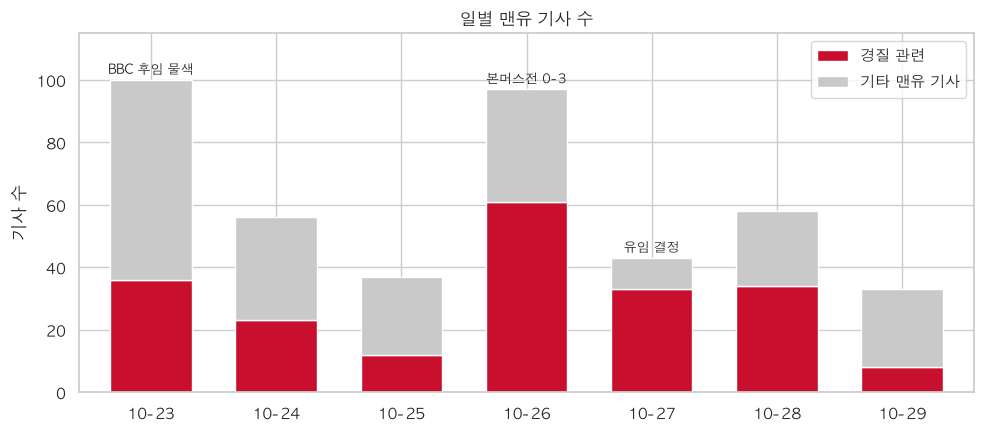

In [13]:
daily = df.groupby('date').agg(total=('id', 'size'), manager=('manager', 'sum'))
daily['other'] = daily.total - daily.manager
daily['manager_share'] = daily.manager / daily.total
display(daily)

ax = daily[['manager', 'other']].plot.bar(stacked=True, figsize=(10, 4.5), color=['#c8102e', '#c9c9c9'], width=0.65)
ax.legend(['경질 관련', '기타 맨유 기사'])
events = {'2026-10-23': 'BBC 후임 물색', '2026-10-26': '본머스전 0-3', '2026-10-27': '유임 결정'}
for i, d in enumerate(daily.index):
    if d in events:
        ax.annotate(events[d], (i, daily.total[d] + 2), ha='center', fontsize=9)
ax.set_xticklabels([d[5:] for d in daily.index], rotation=0)
ax.set(title='일별 맨유 기사 수', xlabel='', ylabel='기사 수')
ax.set_ylim(0, daily.total.max() * 1.15)
plt.tight_layout(); plt.show()

### 5-3. 시간대별 기사량
영국 경기가 끝나는 자정 무렵과 현지 보도가 정리되는 아침 7~8시에 기사가 몰립니다.

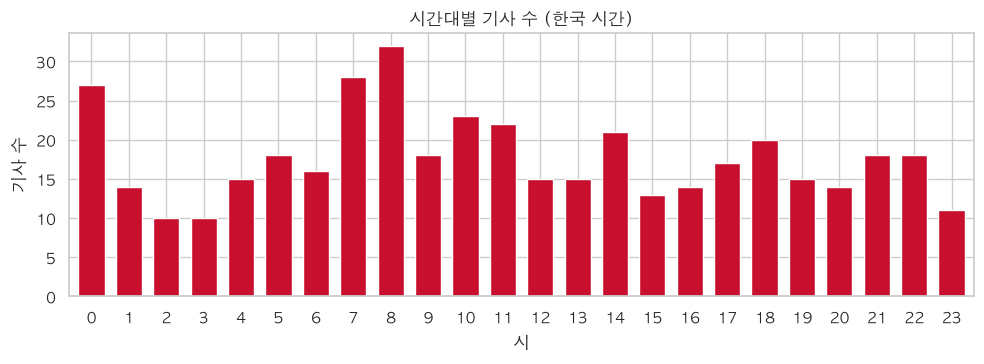

In [14]:
hourly = df.groupby('hour').size().reindex(range(24), fill_value=0)
ax = hourly.plot.bar(figsize=(10, 3.8), color='#c8102e', width=0.7)
ax.set(title='시간대별 기사 수 (한국 시간)', xlabel='시', ylabel='기사 수')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 5-4. 언론사별 기사 수

상위 5개 언론사 비중: 64%


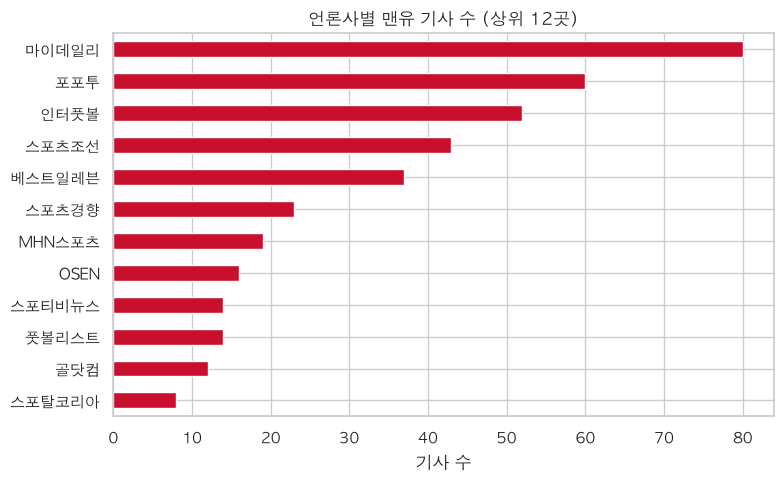

In [15]:
press = df.press.value_counts()
print(f"상위 5개 언론사 비중: {press.head(5).sum() / len(df):.0%}")
ax = press.head(12).sort_values().plot.barh(figsize=(8, 5), color='#c8102e')
ax.set(title='언론사별 맨유 기사 수 (상위 12곳)', xlabel='기사 수', ylabel='')
plt.tight_layout(); plt.show()

### 5-5. 제목에 등장한 인물
후임 후보 중에서는 나겔스만과 하우가 비슷하게 많이 거론됐고, 브루노 페르난데스와 캐릭의 불화도 큰 줄기였습니다.

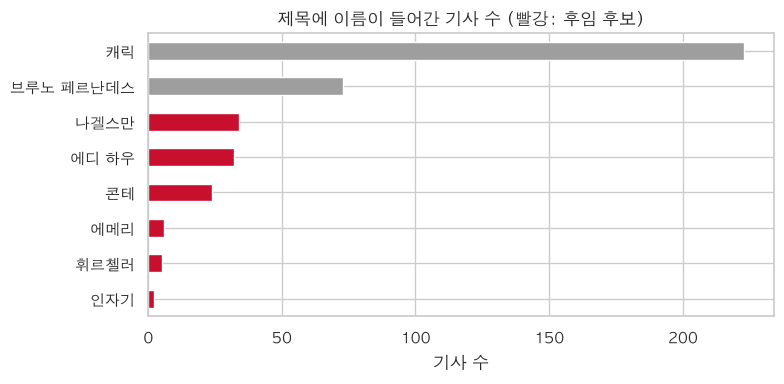

In [16]:
PEOPLE = {'캐릭': '캐릭', '브루노 페르난데스': '브루노|페르난데스', '나겔스만': '나겔스만', '에디 하우': '하우',
          '콘테': '콘테', '에메리': '에메리', '휘르첼러': '휘르첼러', '인자기': '인자기'}
people = pd.Series({k: df.title.str.contains(v).sum() for k, v in PEOPLE.items()}).sort_values()
candidates = {'나겔스만', '에디 하우', '콘테', '에메리', '휘르첼러', '인자기'}
ax = people.plot.barh(figsize=(8, 4), color=['#c8102e' if k in candidates else '#9e9e9e' for k in people.index])
ax.set(title='제목에 이름이 들어간 기사 수 (빨강: 후임 후보)', xlabel='기사 수', ylabel='')
plt.tight_layout(); plt.show()

### 5-6. 제목 톤과 조회수
부정적인 제목이 41%로 가장 많지만, 톤별 조회수 중앙값은 큰 차이가 없습니다. 조회수는 오른쪽으로 크게 치우쳐 있어 로그 축으로 봅니다.

,size,median,mean,share
tone,,,,
부정,174,3448.0,5217.390805,41%
중립,197,3082.0,6007.888325,46%
혼합,25,4280.0,6123.880000,6%
긍정,28,3732.5,5888.892857,7%


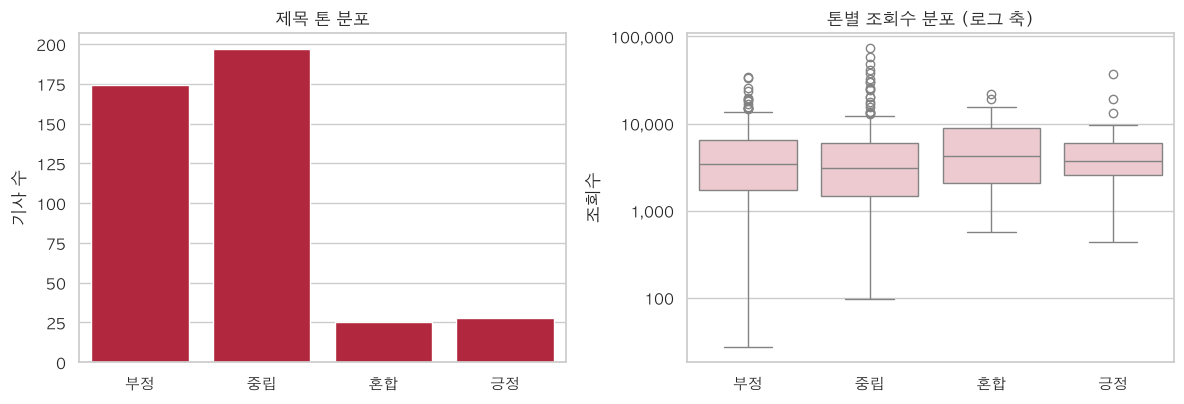

In [17]:
order = ['부정', '중립', '혼합', '긍정']
tone_stat = df.groupby('tone').views.agg(['size', 'median', 'mean']).reindex(order)
tone_stat['share'] = (tone_stat['size'] / len(df)).map('{:.0%}'.format)
display(tone_stat)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.countplot(data=df, x='tone', order=order, ax=axes[0], color='#c8102e')
axes[0].set(title='제목 톤 분포', xlabel='', ylabel='기사 수')
sns.boxplot(data=df, x='tone', y='views', order=order, ax=axes[1], color='#f2c4cb', showfliers=True)
axes[1].set_yscale('log')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{int(v):,}'))
axes[1].set(title='톤별 조회수 분포 (로그 축)', xlabel='', ylabel='조회수')
plt.tight_layout(); plt.show()

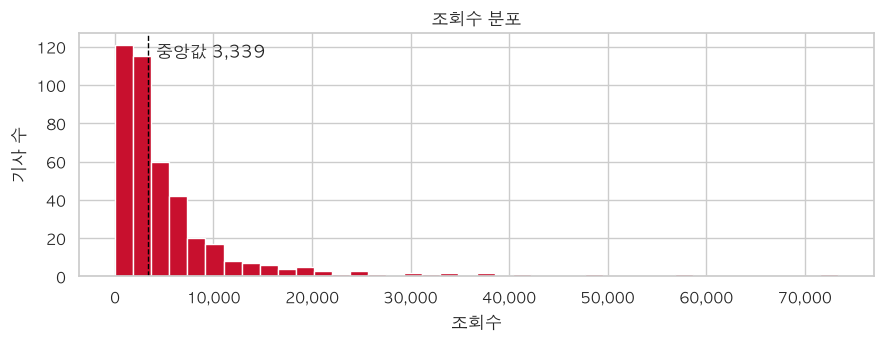

In [18]:
ax = df.views.plot.hist(bins=40, figsize=(9, 3.6), color='#c8102e', logy=False)
ax.axvline(df.views.median(), color='black', ls='--', lw=1)
ax.annotate(f"중앙값 {int(df.views.median()):,}", (df.views.median(), ax.get_ylim()[1] * 0.9), xytext=(6, 0), textcoords='offset points')
ax.set(title='조회수 분포', xlabel='조회수', ylabel='기사 수')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{int(v):,}'))
plt.tight_layout(); plt.show()

### 5-7. 경질 관련 기사 vs 나머지

In [19]:
cmp = df.groupby('manager').agg(n=('id', 'size'), median_views=('views', 'median'),
                                neg_share=('tone', lambda s: (s == '부정').mean()))
cmp.index = ['기타', '경질 관련']
cmp['median_views'] = cmp.median_views.astype(int)
cmp['neg_share'] = cmp.neg_share.map('{:.0%}'.format)
cmp

,n,median_views,neg_share
기타,217,3211,45%
경질 관련,207,3423,37%


### 5-8. 기자별 부정 제목 비율
맨유 기사 5건 이상 기자만 비교합니다. 빨간 막대가 60% 기준을 넘어 제외한 기자입니다. 기사 수가 5~6건인 기자는 한두 건 차이로 순위가 바뀔 수 있습니다.

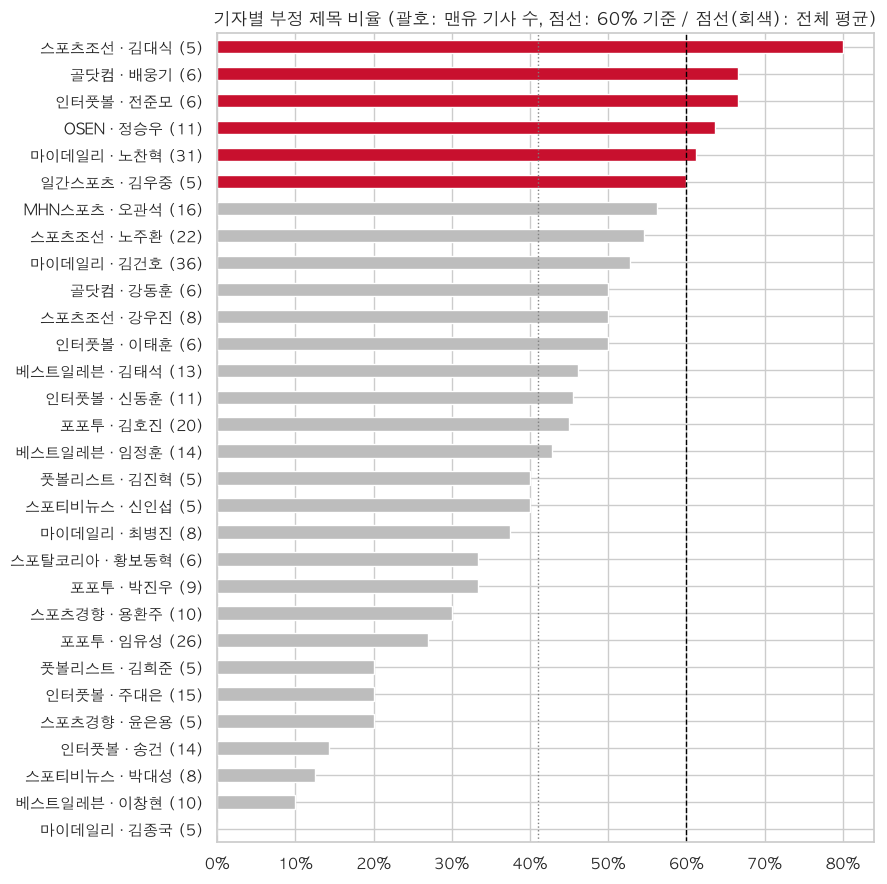

In [20]:
r = rep.assign(label=rep.press + ' · ' + rep.reporter + ' (' + rep.n.astype(str) + ')').sort_values('neg_share')
ax = r.plot.barh(x='label', y='neg_share', figsize=(9, 9), legend=False,
                 color=['#c8102e' if v >= NEG_CUTOFF else '#bdbdbd' for v in r.neg_share])
ax.axvline(NEG_CUTOFF, color='black', ls='--', lw=1)
ax.axvline((df.tone == '부정').mean(), color='gray', ls=':', lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title='기자별 부정 제목 비율 (괄호: 맨유 기사 수, 점선: 60% 기준 / 점선(회색): 전체 평균)', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

### 5-9. 조회수 상위 10건
전술 분석보다 팬 이야기, 감독 후보설, 경질 속보가 상위를 차지합니다.

In [21]:
df.nlargest(10, 'views')[['date', 'press', 'reporter', 'tone', 'views', 'title']].reset_index(drop=True)

,date,press,reporter,tone,views,title
0,2026-10-25,엑스포츠뉴스,권동환,중립,73365,"'감독 경질 될 때까지 매일 가슴 공개!'…맨유 미녀 서포터 파격 선언에 난리→팬들은 ""캐릭 종신! 재계약 추진하자"""
1,2026-10-28,OSEN,서정환,중립,58617,“캐릭 경질될 때까지 매일 가슴 사진 올린다”…맨유 팬의 파격 선언에 팬들 “캐릭 제발 계속 감독해라”
2,2026-10-26,마이데일리,최병진,중립,48539,"이럴 수가! '충격 그 자체'...맨체스터 유나이티드 '드림 감독'으로 낙점! ""단장이 매우 높게 평가""→이미 지난 해에도 러브콜 보냈다"
3,2026-10-24,스포티비뉴스,박대성,중립,41156,"‘오피셜’ 공식발표, 캐릭 맨체스터 유나이티드 감독 경질→후임으로 거론됐던 콘테 “진전된 협상 전혀 없다, 근거없는 보도” 정면 반박"
4,2026-10-27,MHN스포츠,오관석,중립,37912,맨체스터 유나이티드 결국 '파격 결단' 임박! '3무 5패' 캐릭 경질→차기 감독 선임 작업 착수...나겔스만·하우 2파전
5,2026-10-23,마이데일리,노찬혁,긍정,36858,"말 그대로 '초대박'...맨체스터 유나이티드 '감독 교체' 청신호! 'HERE WE GO' 캐릭 경질→'쏘니 전 스승' 후임 가능, ""시..."
6,2026-10-24,마이데일리,노찬혁,부정,34125,"말 그대로 '미친 영입'...맨체스터 유나이티드 '브페 후계자' 낙점! '2골 1도움' 참사 안긴 '제2의 메시' 러브콜, 레알 '바이백..."
7,2026-10-25,마이데일리,최병진,부정,33534,"'처참하다' 캐릭의 결단 '악수'로...맨체스터 유나이티드, '돌아온 골칫거리' 겨울에 결국 매각한다! ""에버턴과 겨울 이적 협상 진행"""
8,2026-10-26,포포투,임유성,중립,32029,"[오피셜] 맨유 처참하게 무너뜨린 코모의 '그리스 폭격기', 2031년까지 재계약"
9,2026-10-26,마이데일리,최병진,중립,30146,"세상에! 결국 '깜짝 임대?'...맨체스터 유나이티드, '라이벌' 맨시티 LB 다시 노린다→EPL 출전 '0회'로 입지 '대위기'"


## 6. 정리

- 일주일 동안 맨유 기사 424건 중 **약 49%(207건)가 캐릭 감독 경질** 이야기였습니다.
- 기사량은 **10/23(BBC 후임 물색 보도)**과 **10/26(본머스전 0-3)**에 정점을 찍었고, **10/27 유임 결정** 당일에는 경질 관련 비중이 77%까지 올라갔습니다.
- 후임 후보 중에서는 **나겔스만(34건)과 하우(32건)**가 가장 많이 거론됐고, 콘테가 뒤를 이었습니다.
- 제목의 **41%가 부정적인 표현**을 썼지만 톤별 조회수 중앙값은 비슷해, **자극적인 제목이 클릭을 보장하지는 않았습니다**.
- 상위 5개 언론사가 전체 기사의 64%를 썼고, 마이데일리가 80건으로 가장 많습니다.
- 부정 비율 60% 이상인 기자 6명의 기사 64건을 제외한 필터링 파일을 함께 저장했습니다.

**한계**: 톤과 경질 관련 여부는 제목·요약 키워드로 분류해서 오분류가 있을 수 있고, 조회수는 수집 시점의 누적값이라 최근 기사일수록 낮게 나옵니다.